# Lot-Sizing: Entendiendo paso a paso el Rockafellian con CVaR

Vamos a construir todo desde cero para entender exactamente qué pasa.

**El problema:** Tenemos que decidir cuánto producir en cada período $t=1,\ldots,T$ **antes** de observar la demanda. Si la producción acumulada no alcanza para cubrir la demanda acumulada en algún período, hay un shortfall (faltante).

**La restricción:** Queremos que, con probabilidad al menos $1-\alpha = 90\%$, no haya shortfall en **ningún** período simultáneamente (joint chance constraint).


## Paso 1: Generar los datos

Lo primero es entender cómo es la demanda.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(42)

T = 5       # períodos
N = 500     # escenarios
alpha = 0.10  # nivel de riesgo (queremos 90% reliability)

# Costos de producción
c = np.random.uniform(2, 5, T)
print("Costos de producción:", c.round(2))

# Demanda: LogNormal(3, 0.5)
demand = np.random.lognormal(mean=3, sigma=0.5, size=(N, T))

print(f"\nDemanda por período:")
print(f"  Media:       {demand.mean(axis=0).round(1)}")
print(f"  Percentil 90: {np.percentile(demand, 90, axis=0).round(1)}")
print(f"  Percentil 95: {np.percentile(demand, 95, axis=0).round(1)}")
print(f"  Máximo:       {demand.max(axis=0).round(1)}")
print(f"\nMedia global por período: {demand.mean():.1f}")


Costos de producción: [3.12 4.85 4.2  3.8  2.47]

Demanda por período:
  Media:       [22.5 23.  23.1 22.1 22.7]
  Percentil 90: [37.1 37.1 38.7 36.4 36.9]
  Percentil 95: [43.2 44.8 44.1 43.9 46.5]
  Máximo:       [ 69.1  88.5  80.6  87.3 108.4]

Media global por período: 22.7


## Paso 2: La función de pérdida $L(x, \xi)$

Para la chance constraint conjunta (todos los períodos a la vez), definimos:

$$L(x, \xi) = \max_{t=1,\ldots,T} \left( \sum_{k=1}^t D_k(\xi) - \sum_{k=1}^t x_k \right)$$

Es decir: el peor shortfall acumulado a lo largo del horizonte.

- Si $L \leq 0$: la producción acumulada cubre la demanda en **todos** los períodos → escenario factible.
- Si $L > 0$: hay al menos un período donde la demanda acumulada supera la producción → violación.

La chance constraint es: $\mathbb{P}(L(x,\xi) \leq 0) \geq 1 - \alpha$.

In [6]:
def compute_loss(x, demand):
    """
    L_k = max_t (demanda_acum_t - producción_acum_t) para cada escenario k.

    x: (T,) decisiones de producción
    demand: (N, T) escenarios de demanda
    Retorna: L de tamaño (N,)
    """
    cum_demand = np.cumsum(demand, axis=1)   # (N, T) demanda acumulada
    cum_prod = np.cumsum(x)                   # (T,) producción acumulada
    shortfall = cum_demand - cum_prod[None, :]  # (N, T) shortfall por período
    L = np.max(shortfall, axis=1)              # (N,) peor shortfall
    return L

# Ejemplo: si producimos 30 unidades por período
x_ejemplo = np.full(T, 30.0)
L_ejemplo = compute_loss(x_ejemplo, demand)

print(f"Producción por período: {x_ejemplo}")
print(f"Producción acumulada:   {np.cumsum(x_ejemplo)}")
print(f"\nDemanda acumulada media: {np.cumsum(demand.mean(axis=0)).round(1)}")
print(f"\nL (pérdida) para los primeros 10 escenarios:")
for k in range(10):
    status = "✓ factible" if L_ejemplo[k] <= 0 else "✗ violación"
    print(f"  Escenario {k}: L = {L_ejemplo[k]:>7.2f}  {status}")

n_factibles = np.sum(L_ejemplo <= 0)
print(f"\nEscenarios factibles: {n_factibles}/{N} = {100*n_factibles/N:.1f}%")
print(f"Reliability: {100*np.mean(L_ejemplo <= 0):.1f}%")


Producción por período: [30. 30. 30. 30. 30.]
Producción acumulada:   [ 30.  60.  90. 120. 150.]

Demanda acumulada media: [ 22.5  45.5  68.7  90.7 113.4]

L (pérdida) para los primeros 10 escenarios:
  Escenario 0: L =   -3.62  ✓ factible
  Escenario 1: L =  -17.35  ✓ factible
  Escenario 2: L =  -13.78  ✓ factible
  Escenario 3: L =   39.30  ✗ violación
  Escenario 4: L =  -12.87  ✓ factible
  Escenario 5: L =  -11.47  ✓ factible
  Escenario 6: L =   42.40  ✗ violación
  Escenario 7: L =    1.21  ✗ violación
  Escenario 8: L =  -19.76  ✓ factible
  Escenario 9: L =    2.72  ✗ violación

Escenarios factibles: 323/500 = 64.6%
Reliability: 64.6%


In [9]:
def compute_loss(x, demand):
    """
    L_k = max_t (demanda_acum_t - producción_acum_t) para cada escenario k.

    x: (T,) decisiones de producción
    demand: (N, T) escenarios de demanda
    Retorna: L de tamaño (N,)
    """
    cum_demand = np.cumsum(demand, axis=1)   # (N, T) demanda acumulada
    cum_prod = np.cumsum(x)                   # (T,) producción acumulada
    shortfall = cum_demand - cum_prod[None, :]  # (N, T) shortfall por período
    L = np.max(shortfall, axis=1)              # (N,) peor shortfall
    return L

# Ejemplo: si producimos 60 unidades por período
x_ejemplo = np.full(T, 40.0)
L_ejemplo = compute_loss(x_ejemplo, demand)

print(f"Producción por período: {x_ejemplo}")
print(f"Producción acumulada:   {np.cumsum(x_ejemplo)}")
print(f"\nDemanda acumulada media: {np.cumsum(demand.mean(axis=0)).round(1)}")
print(f"\nL (pérdida) para los primeros 10 escenarios:")
for k in range(10):
    status = "✓ factible" if L_ejemplo[k] <= 0 else "✗ violación"
    print(f"  Escenario {k}: L = {L_ejemplo[k]:>7.2f}  {status}")

n_factibles = np.sum(L_ejemplo <= 0)
print(f"\nEscenarios factibles: {n_factibles}/{N} = {100*n_factibles/N:.1f}%")
print(f"Reliability: {100*np.mean(L_ejemplo <= 0):.1f}%")


Producción por período: [40. 40. 40. 40. 40.]
Producción acumulada:   [ 40.  80. 120. 160. 200.]

Demanda acumulada media: [ 22.5  45.5  68.7  90.7 113.4]

L (pérdida) para los primeros 10 escenarios:
  Escenario 0: L =  -16.91  ✓ factible
  Escenario 1: L =  -27.35  ✓ factible
  Escenario 2: L =  -23.78  ✓ factible
  Escenario 3: L =   19.30  ✗ violación
  Escenario 4: L =  -25.12  ✓ factible
  Escenario 5: L =  -21.47  ✓ factible
  Escenario 6: L =    5.92  ✗ violación
  Escenario 7: L =   -8.79  ✓ factible
  Escenario 8: L =  -29.76  ✓ factible
  Escenario 9: L =   -8.69  ✓ factible

Escenarios factibles: 452/500 = 90.4%
Reliability: 90.4%


## Paso 3: ¿Qué es el CVaR y cómo se calcula?

El $\text{CVaR}_\alpha(L)$ tiene esta representación variacional:

$$\text{CVaR}_\alpha(L) = \min_{\eta \in \mathbb{R}} \left\{ \eta + \frac{1}{\alpha} \mathbb{E}\left[(L - \eta)^+\right] \right\}$$

Con la SAA (Sample Average Approximation), reemplazamos la esperanza por el promedio muestral:

$$\text{CVaR}_\alpha^N(L) = \min_{\eta} \left\{ \eta + \frac{1}{\alpha N} \sum_{k=1}^N \max(L_k - \eta, 0) \right\}$$

La $\eta$ óptima resulta ser el cuantil $(1-\alpha)$ de $L$ (el VaR).

**Propiedad clave (conservatividad):**

$$\text{CVaR}_\alpha(L) \leq 0 \quad \Longrightarrow \quad \mathbb{P}(L \leq 0) \geq 1 - \alpha$$

La implicación es en **un solo sentido**. Puede pasar que $\text{CVaR} > 0$ pero la chance constraint sí se cumpla.

In [10]:
def compute_cvar(L, alpha):
    """
    Calcula CVaR_alpha a partir de muestras.
    Retorna: (cvar, eta_optimo)
    """
    N = len(L)
    sorted_L = np.sort(L)

    # eta óptimo = cuantil (1-alpha) = percentil 90 cuando alpha=0.10
    idx = int(np.ceil((1 - alpha) * N)) - 1
    eta = sorted_L[idx]

    # CVaR = eta + (1/alpha) * promedio de (L - eta)^+
    cvar = eta + (1.0 / alpha) * np.mean(np.maximum(L - eta, 0.0))

    return cvar, eta

# Calculemos para el ejemplo anterior (x = 30 por período)
cvar, eta = compute_cvar(L_ejemplo, alpha)

print(f"Para x = {x_ejemplo[0]:.0f} por período:")
print(f"  η (VaR, percentil 90 de L) = {eta:.2f}")
print(f"  CVaR_0.10 = {cvar:.2f}")
print(f"  Reliability = {100*np.mean(L_ejemplo <= 0):.1f}%")
print()

if cvar <= 0:
    print("  CVaR ≤ 0 → la surrogate CVaR dice: FACTIBLE")
    print("  (y por conservatividad, la CC original también)")
else:
    print(f"  CVaR = {cvar:.2f} > 0 → la surrogate CVaR dice: INFACTIBLE")
    rel = 100*np.mean(L_ejemplo <= 0)
    if rel >= 90:
        print(f"  PERO reliability = {rel:.1f}% ≥ 90% → la CC original SÍ se cumple")
        print("  → Esto es el GAP DE CONSERVADURISMO del CVaR")
    else:
        print(f"  Y reliability = {rel:.1f}% < 90% → la CC original tampoco se cumple")


Para x = 40 por período:
  η (VaR, percentil 90 de L) = -0.35
  CVaR_0.10 = 11.27
  Reliability = 90.4%

  CVaR = 11.27 > 0 → la surrogate CVaR dice: INFACTIBLE
  PERO reliability = 90.4% ≥ 90% → la CC original SÍ se cumple
  → Esto es el GAP DE CONSERVADURISMO del CVaR


## Paso 4: Explorar el panorama para distintos $\bar{x}$

Antes de optimizar, entendamos qué pasa si producimos **al máximo** ($x_t = \bar{x}$ para todo $t$). Esto da la **mejor reliability posible** para cada capacidad.

Si ni siquiera produciendo al máximo se puede cumplir la restricción, entonces el problema es estructuralmente infactible.

In [11]:
print("="*70)
print("¿Qué pasa produciendo al MÁXIMO para cada capacidad?")
print("="*70)
print(f"{'xbar':>6} {'Prod.Total':>10} {'Rel.':>8} {'CVaR':>10} {'CC?':>12} {'CVaR?':>14}")
print("-"*70)

for xbar in [100, 50, 45, 40, 38, 35, 30, 25]:
    x = np.full(T, xbar)
    L = compute_loss(x, demand)
    cvar, eta = compute_cvar(L, alpha)
    rel = 100 * np.mean(L <= 0)

    cc_ok = "CC-fact." if rel >= 90 else "CC-infact."
    cvar_ok = "CVaR-fact." if cvar <= 0 else f"CVaR-inf.(u*={cvar:.1f})"

    print(f"{xbar:>6d} {xbar*T:>10d} {rel:>7.1f}% {cvar:>10.2f} {cc_ok:>12} {cvar_ok:>14}")

print()
print("Observaciones:")
print("  - xbar=50: AMBOS factibles (CC y CVaR)")
print("  - xbar=40: CC factible (90.4%) pero CVaR infactible (u*=11.3)")
print("  - xbar=35: AMBOS infactibles")
print("  - La franja xbar=40-45 es donde está el gap de conservadurismo")


¿Qué pasa produciendo al MÁXIMO para cada capacidad?
  xbar Prod.Total     Rel.       CVaR          CC?          CVaR?
----------------------------------------------------------------------
   100        500   100.0%     -53.22     CC-fact.     CVaR-fact.
    50        250    96.6%      -1.64     CC-fact.     CVaR-fact.
    45        225    94.2%       4.44     CC-fact. CVaR-inf.(u*=4.4)
    40        200    90.4%      11.27     CC-fact. CVaR-inf.(u*=11.3)
    38        190    86.6%      14.33   CC-infact. CVaR-inf.(u*=14.3)
    35        175    81.4%      19.80   CC-infact. CVaR-inf.(u*=19.8)
    30        150    64.6%      31.70   CC-infact. CVaR-inf.(u*=31.7)
    25        125    43.8%      47.94   CC-infact. CVaR-inf.(u*=47.9)

Observaciones:
  - xbar=50: AMBOS factibles (CC y CVaR)
  - xbar=40: CC factible (90.4%) pero CVaR infactible (u*=11.3)
  - xbar=35: AMBOS infactibles
  - La franja xbar=40-45 es donde está el gap de conservadurismo


## Paso 5: El Rockafellian — ¿qué optimiza exactamente?

El problema Rockafellian penalizado es:

$$\min_{u \text{ and } x \in X} \quad f_0(x) + \frac{\gamma}{2} u^2$$
$$\text{s.a.} \quad \text{CVaR}_\alpha(L(x,\xi)) \leq u, \quad u \geq 0$$

O equivalentemente (sustituyendo $u = \max(\text{CVaR}_\alpha(L), 0)$):

$$\min_{x \in X} \quad \underbrace{\sum_t c_t x_t}_{\text{costo producción}} + \frac{\gamma}{2} \underbrace{\left[\max(\text{CVaR}_\alpha(L(x,\xi)), 0)\right]^2}_{\text{penalización por violar CVaR}}$$

- Si $\gamma$ es **pequeño**: domina minimizar costos → se produce poco → $u$ grande.
- Si $\gamma$ es **grande**: domina reducir $u$ → se produce mucho → u pequeño.
- Cuando $\gamma \to \infty$: $u \to u^* = \inf_x \max(\text{CVaR}_\alpha(L(x,\xi)), 0)$.

**Clave:** $u^*$ mide la distancia a factibilidad de la **surrogate CVaR**, NO de la chance constraint original.

In [12]:
from scipy.optimize import minimize

def rockafellian_objective(x, gamma, demand, alpha, c):
    """Objetivo del Rockafellian: costo + (gamma/2)*u^2"""
    L = compute_loss(x, demand)
    cvar, _ = compute_cvar(L, alpha)
    u = max(cvar, 0.0)
    prod_cost = np.dot(c, x)
    return prod_cost + (gamma / 2.0) * u**2

# Probemos con xbar=50, gamma=100
xbar = 50
gamma = 100
x0 = np.full(T, 10.0)  # empezar con poca producción
bounds = [(0, xbar)] * T

res = minimize(rockafellian_objective, x0, args=(gamma, demand, alpha, c),
               method='L-BFGS-B', bounds=bounds,
               options={'maxiter': 3000, 'ftol': 1e-14})

x_opt = res.x
L_opt = compute_loss(x_opt, demand)
cvar_opt, eta_opt = compute_cvar(L_opt, alpha)
u_opt = max(cvar_opt, 0)

print(f"xbar = {xbar}, gamma = {gamma}")
print(f"x óptimo: {x_opt.round(2)}")
print(f"Costo producción: ${np.dot(c, x_opt):.2f}")
print(f"CVaR = {cvar_opt:.4f}")
print(f"u = max(CVaR, 0) = {u_opt:.4f}")
print(f"Penalización = (γ/2)*u² = {(gamma/2)*u_opt**2:.4f}")
print(f"Reliability = {100*np.mean(L_opt <= 0):.1f}%")


xbar = 50, gamma = 100
x óptimo: [50.   50.   39.71 30.4  22.28]
Costo producción: $735.81
CVaR = 0.3085
u = max(CVaR, 0) = 0.3085
Penalización = (γ/2)*u² = 4.7588
Reliability = 96.0%


## Paso 6: El path diagnóstico — barriendo $\gamma$

Ahora corremos el Rockafellian para una secuencia de $\gamma$ crecientes y observamos cómo evoluciona $u$.

**Si u → 0:** La surrogate CVaR es factible. El problema tiene solución.

**Si u → u* > 0:** La surrogate CVaR es infactible. $u^*$ mide cuánto "falta".

Probemos con dos capacidades: $\bar{x} = 50$ y $\bar{x} = 40$.

In [20]:
def run_rockafellian_path(xbar, gamma_values, demand, alpha, c):
    """Corre el Rockafellian para una secuencia de gammas."""
    T = demand.shape[1]
    results = []
    x0 = np.full(T, 5.0)  # empezar bajo para ver la dinámica

    for gamma in gamma_values:
        res = minimize(rockafellian_objective, x0,
                       args=(gamma, demand, alpha, c),
                       method='L-BFGS-B', bounds=[(0, xbar)]*T,
                       options={'maxiter': 3000, 'ftol': 1e-14})
        x0 = res.x.copy()  # warm start

        L = compute_loss(res.x, demand)
        cvar, eta = compute_cvar(L, alpha)
        u = max(cvar, 0)

        results.append({
            'gamma': gamma,
            'u': u,
            'cost': np.dot(c, res.x),
            'reliability': 100 * np.mean(L <= 0),
            'cvar': cvar,
            'x': res.x.copy()
        })

    return results

gamma_values = np.logspace(-2, 5, 20)

print("Corriendo xbar=50...")
res_50 = run_rockafellian_path(50, gamma_values, demand, alpha, c)
print("Corriendo xbar=40...")
res_40 = run_rockafellian_path(40, gamma_values, demand, alpha, c)
print("Listo!")


Corriendo xbar=50...
Corriendo xbar=40...
Listo!


## Paso 7: Visualizar los resultados

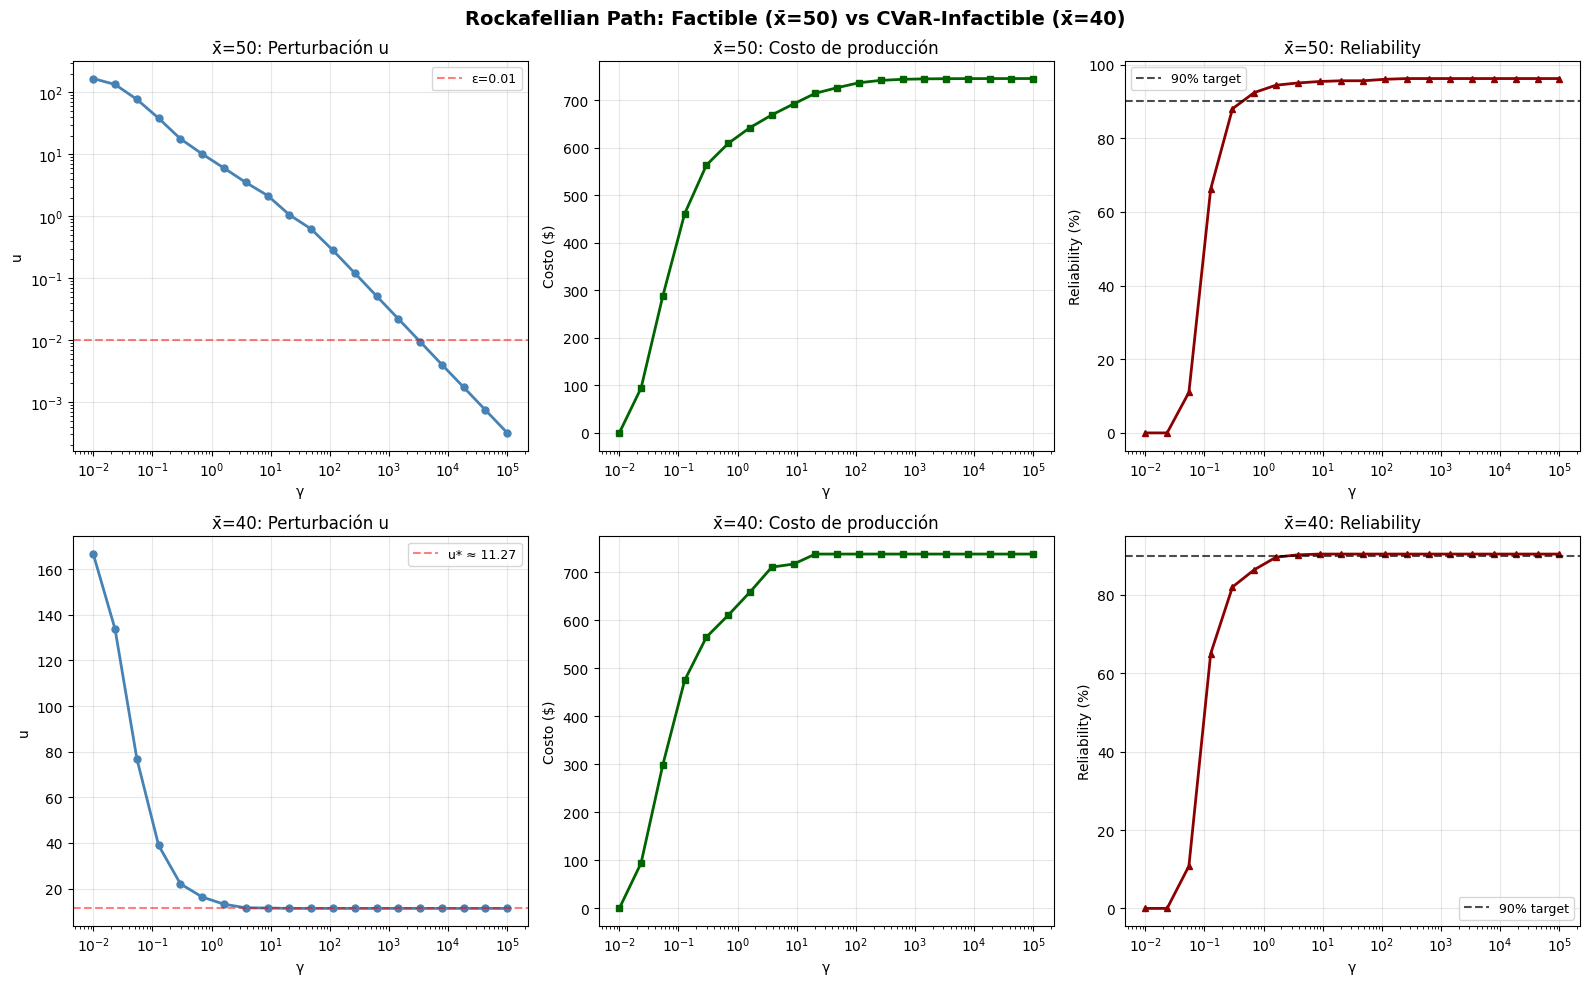

In [21]:
fig, axes = plt.subplots(2, 3, figsize=(16, 10))

for row, (results, xbar_label) in enumerate([(res_50, "x̄=50"), (res_40, "x̄=40")]):
    gammas = [r['gamma'] for r in results]
    us = [r['u'] for r in results]
    costs = [r['cost'] for r in results]
    rels = [r['reliability'] for r in results]

    # Panel A: Perturbación u
    ax = axes[row, 0]
    ax.plot(gammas, us, 'o-', lw=2, ms=5, color='steelblue')
    ax.set_xscale('log')
    ax.set_xlabel('γ')
    ax.set_ylabel('u')
    ax.set_title(f'{xbar_label}: Perturbación u')
    ax.grid(True, alpha=0.3)
    final_u = us[-1]
    if final_u > 0.01:
        ax.axhline(y=final_u, color='red', ls='--', alpha=0.5,
                    label=f'u* ≈ {final_u:.2f}')
    else:
        ax.set_yscale('log')
        ax.axhline(y=0.01, color='red', ls='--', alpha=0.5, label='ε=0.01')
    ax.legend(fontsize=9)

    # Panel B: Costo
    ax = axes[row, 1]
    ax.plot(gammas, costs, 's-', lw=2, ms=5, color='darkgreen')
    ax.set_xscale('log')
    ax.set_xlabel('γ')
    ax.set_ylabel('Costo ($)')
    ax.set_title(f'{xbar_label}: Costo de producción')
    ax.grid(True, alpha=0.3)

    # Panel C: Reliability
    ax = axes[row, 2]
    ax.plot(gammas, rels, '^-', lw=2, ms=5, color='darkred')
    ax.set_xscale('log')
    ax.axhline(y=90, color='black', ls='--', lw=1.5, alpha=0.7, label='90% target')
    ax.set_xlabel('γ')
    ax.set_ylabel('Reliability (%)')
    ax.set_title(f'{xbar_label}: Reliability')
    ax.grid(True, alpha=0.3)
    ax.legend(fontsize=9)

plt.suptitle('Rockafellian Path: Factible (x̄=50) vs CVaR-Infactible (x̄=40)',
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()


In [16]:
def run_rockafellian_path(xbar, gamma_values, demand, alpha, c):
    """Corre el Rockafellian para una secuencia de gammas."""
    T = demand.shape[1]
    results = []
    x0 = np.full(T, 5.0)  # empezar bajo para ver la dinámica

    for gamma in gamma_values:
        res = minimize(rockafellian_objective, x0,
                       args=(gamma, demand, alpha, c),
                       method='L-BFGS-B', bounds=[(0, xbar)]*T,
                       options={'maxiter': 3000, 'ftol': 1e-14})
        x0 = res.x.copy()  # warm start

        L = compute_loss(res.x, demand)
        cvar, eta = compute_cvar(L, alpha)
        u = max(cvar, 0)

        results.append({
            'gamma': gamma,
            'u': u,
            'cost': np.dot(c, res.x),
            'reliability': 100 * np.mean(L <= 0),
            'cvar': cvar,
            'x': res.x.copy()
        })

    return results

gamma_values = np.logspace(-2, 5, 20)

print("Corriendo xbar=48...")
res_50 = run_rockafellian_path(48, gamma_values, demand, alpha, c)
print("Corriendo xbar=42...")
res_40 = run_rockafellian_path(42, gamma_values, demand, alpha, c)
print("Listo!")


Corriendo xbar=48...
Corriendo xbar=42...
Listo!


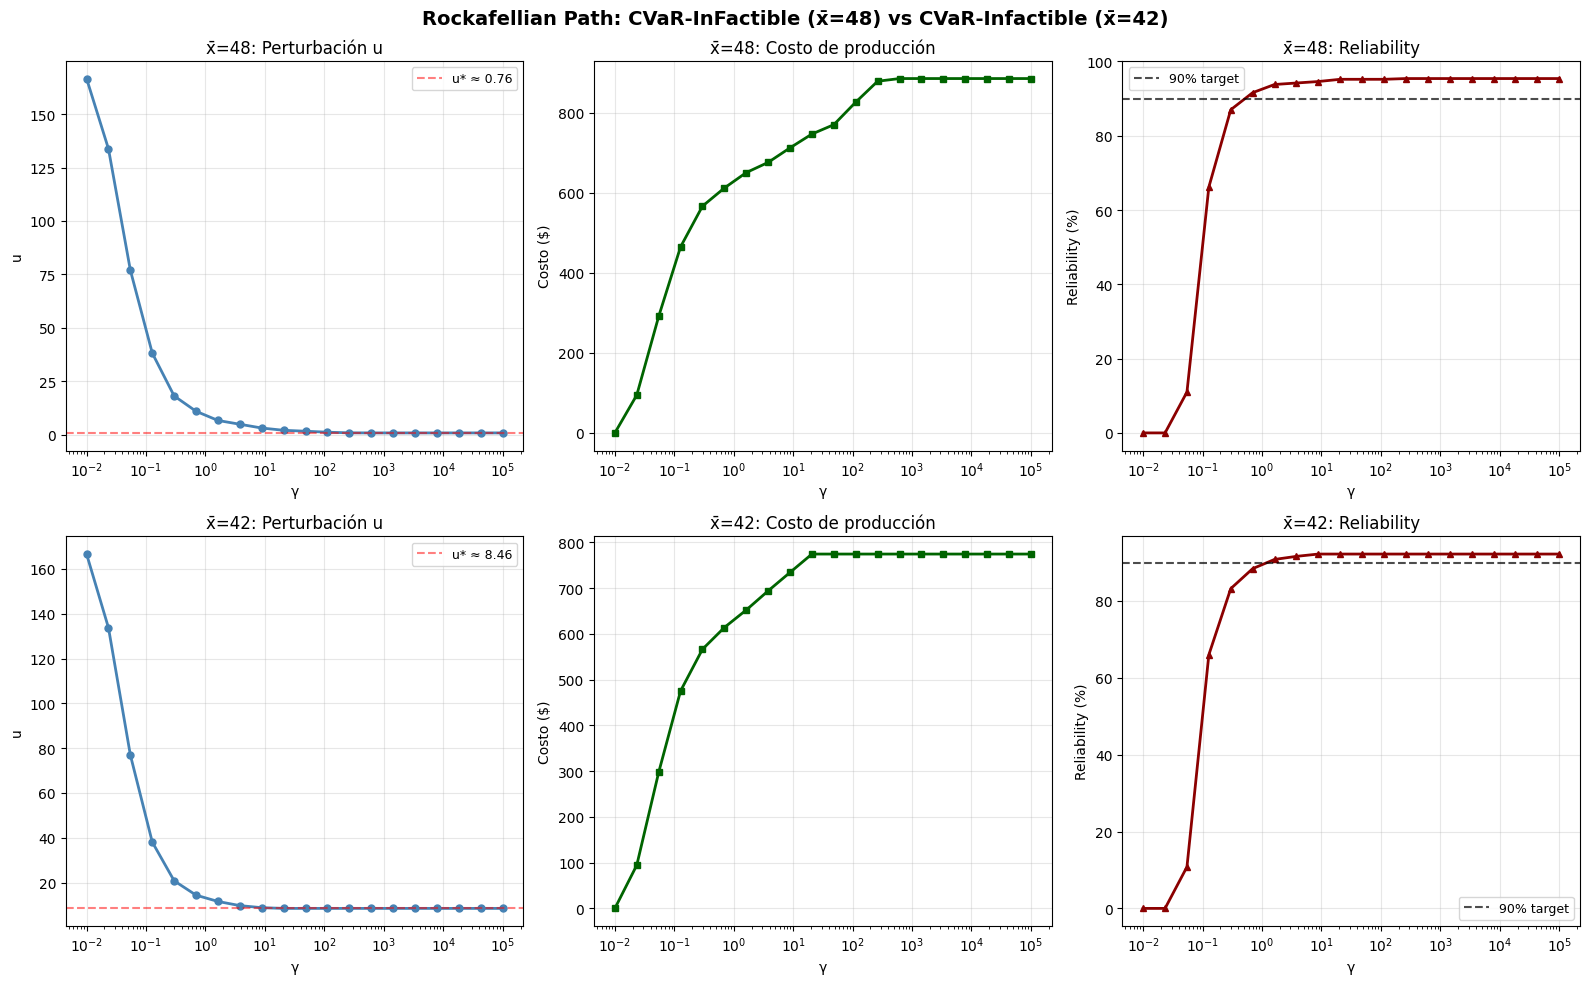

In [19]:
fig, axes = plt.subplots(2, 3, figsize=(16, 10))

for row, (results, xbar_label) in enumerate([(res_50, "x̄=48"), (res_40, "x̄=42")]):
    gammas = [r['gamma'] for r in results]
    us = [r['u'] for r in results]
    costs = [r['cost'] for r in results]
    rels = [r['reliability'] for r in results]

    # Panel A: Perturbación u
    ax = axes[row, 0]
    ax.plot(gammas, us, 'o-', lw=2, ms=5, color='steelblue')
    ax.set_xscale('log')
    ax.set_xlabel('γ')
    ax.set_ylabel('u')
    ax.set_title(f'{xbar_label}: Perturbación u')
    ax.grid(True, alpha=0.3)
    final_u = us[-1]
    if final_u > 0.01:
        ax.axhline(y=final_u, color='red', ls='--', alpha=0.5,
                    label=f'u* ≈ {final_u:.2f}')
    else:
        ax.set_yscale('log')
        ax.axhline(y=0.01, color='red', ls='--', alpha=0.5, label='ε=0.01')
    ax.legend(fontsize=9)

    # Panel B: Costo
    ax = axes[row, 1]
    ax.plot(gammas, costs, 's-', lw=2, ms=5, color='darkgreen')
    ax.set_xscale('log')
    ax.set_xlabel('γ')
    ax.set_ylabel('Costo ($)')
    ax.set_title(f'{xbar_label}: Costo de producción')
    ax.grid(True, alpha=0.3)

    # Panel C: Reliability
    ax = axes[row, 2]
    ax.plot(gammas, rels, '^-', lw=2, ms=5, color='darkred')
    ax.set_xscale('log')
    ax.axhline(y=90, color='black', ls='--', lw=1.5, alpha=0.7, label='90% target')
    ax.set_xlabel('γ')
    ax.set_ylabel('Reliability (%)')
    ax.set_title(f'{xbar_label}: Reliability')
    ax.grid(True, alpha=0.3)
    ax.legend(fontsize=9)

plt.suptitle('Rockafellian Path: CVaR-InFactible (x̄=48) vs CVaR-Infactible (x̄=42)',
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()


## Paso 8: Interpretar los resultados

Imprimamos los datos clave lado a lado.

In [22]:
print(f"{'':>12} {'x̄=50 (CVaR-factible)':>25} {'x̄=40 (CVaR-infactible)':>25}")
print("-"*65)
print(f"{'u final':>12} {res_50[-1]['u']:>25.6f} {res_40[-1]['u']:>25.6f}")
print(f"{'Reliability':>12} {res_50[-1]['reliability']:>24.1f}% {res_40[-1]['reliability']:>24.1f}%")
print(f"{'Costo':>12} {'$'+f'{res_50[-1]["cost"]:.2f}':>25} {'$'+f'{res_40[-1]["cost"]:.2f}':>25}")
print(f"{'CVaR':>12} {res_50[-1]['cvar']:>25.6f} {res_40[-1]['cvar']:>25.6f}")

print()
print("="*65)
print("INTERPRETACIÓN:")
print("="*65)

u50 = res_50[-1]['u']
u40 = res_40[-1]['u']
r50 = res_50[-1]['reliability']
r40 = res_40[-1]['reliability']

print(f"\nCASO x̄=50:")
if u50 < 0.01:
    print(f"  u → {u50:.6f} ≈ 0")
    print(f"  → La surrogate CVaR ES factible")
    print(f"  → Por conservatividad, la CC también (rel={r50:.1f}% ≥ 90%)")
    print(f"  → DIAGNÓSTICO: Problema factible ✓")

print(f"\nCASO x̄=40:")
if u40 > 0.01:
    print(f"  u → {u40:.4f} > 0")
    print(f"  → La surrogate CVaR NO es factible (u*={u40:.2f})")
    if r40 >= 90:
        print(f"  PERO: reliability = {r40:.1f}% ≥ 90%")
        print(f"  → La CC original SÍ se cumple")
        print(f"  → Esto es el GAP DE CONSERVADURISMO del CVaR")
        print(f"  → El CVaR es demasiado exigente: pide más de lo necesario")
    else:
        print(f"  Y: reliability = {r40:.1f}% < 90%")
        print(f"  → La CC original TAMPOCO se cumple")
        print(f"  → DIAGNÓSTICO: Problema realmente infactible ✗")


                 x̄=50 (CVaR-factible)   x̄=40 (CVaR-infactible)
-----------------------------------------------------------------
     u final                  0.000316                 11.272586
 Reliability                     96.2%                     90.4%
       Costo                   $745.55                   $737.43
        CVaR                  0.000316                 11.272586

INTERPRETACIÓN:

CASO x̄=50:
  u → 0.000316 ≈ 0
  → La surrogate CVaR ES factible
  → Por conservatividad, la CC también (rel=96.2% ≥ 90%)
  → DIAGNÓSTICO: Problema factible ✓

CASO x̄=40:
  u → 11.2726 > 0
  → La surrogate CVaR NO es factible (u*=11.27)
  PERO: reliability = 90.4% ≥ 90%
  → La CC original SÍ se cumple
  → Esto es el GAP DE CONSERVADURISMO del CVaR
  → El CVaR es demasiado exigente: pide más de lo necesario


## Paso 9: ¿Qué pasa con capacidades aún más chicas?

Para ver infactibilidad **real** (donde la CC tampoco se cumple), necesitamos $\bar{x}$ más bajo.

In [23]:
print("Corriendo xbar=35...")
res_35 = run_rockafellian_path(35, gamma_values, demand, alpha, c)
print("Corriendo xbar=25...")
res_25 = run_rockafellian_path(25, gamma_values, demand, alpha, c)
print("Listo!")

print(f"\n{'Caso':>10} {'u*':>10} {'Reliability':>12} {'CC':>15} {'CVaR':>15}")
print("-"*65)
for label, res in [("x̄=50", res_50), ("x̄=40", res_40),
                    ("x̄=35", res_35), ("x̄=25", res_25)]:
    u = res[-1]['u']
    r = res[-1]['reliability']
    cc = "✓ factible" if r >= 90 else "✗ infactible"
    cv = "✓ factible" if u < 0.01 else f"✗ u*={u:.2f}"
    print(f"{label:>10} {u:>10.4f} {r:>11.1f}% {cc:>15} {cv:>15}")

print(f"\n→ x̄=35 y x̄=25 son realmente infactibles:")
print(f"  ni la CC ni el CVaR se pueden satisfacer.")
print(f"  u* cuantifica CUÁNTO falta en escala del CVaR.")


Corriendo xbar=35...
Corriendo xbar=25...
Listo!

      Caso         u*  Reliability              CC            CVaR
-----------------------------------------------------------------
     x̄=50     0.0003        96.2%      ✓ factible      ✓ factible
     x̄=40    11.2726        90.4%      ✓ factible      ✗ u*=11.27
     x̄=35    19.7980        81.4%    ✗ infactible      ✗ u*=19.80
     x̄=25    47.9420        43.8%    ✗ infactible      ✗ u*=47.94

→ x̄=35 y x̄=25 son realmente infactibles:
  ni la CC ni el CVaR se pueden satisfacer.
  u* cuantifica CUÁNTO falta en escala del CVaR.


## Resumen

| Capacidad | u* (Rockafellian) | Reliability | CC original | CVaR surrogate | Interpretación |
|:---------:|:---------:|:----------:|:----------:|:-------------:|:--------------|
| x̄=50 | ≈ 0 | 96% | ✓ factible | ✓ factible | Todo bien |
| x̄=40 | ≈ 11.3 | 90% | ✓ factible | ✗ infactible | Gap conservadurismo |
| x̄=35 | ≈ 19.8 | 81% | ✗ infactible | ✗ infactible | Infactibilidad real |
| x̄=25 | ≈ 47.9 | 44% | ✗ infactible | ✗ infactible | Infactibilidad severa |

**Mensajes clave:**
1. $u^*$ mide distancia a factibilidad del **problema CVaR**, no de la chance constraint original.
2. $u^* = 0$ garantiza CC factible (por conservatividad).
3. $u^* > 0$ NO garantiza CC infactible — puede ser el gap de conservadurismo.
4. Para el paper hay que elegir qué contraste mostrar según el mensaje deseado.


---
# PARTE 2: Diseccionando el gap de conservadurismo

Ahora que entendemos el Rockafellian con CVaR, vamos a entender
**por qué** el CVaR dice infactible cuando la CC dice factible.

Para eso necesitamos mirar la distribución de L(x*,ξ) en detalle.

## Paso 10: Anatomía de la distribución de pérdida

Para la solución x* del Rockafellian (γ alto), veamos qué pasa
escenario por escenario.

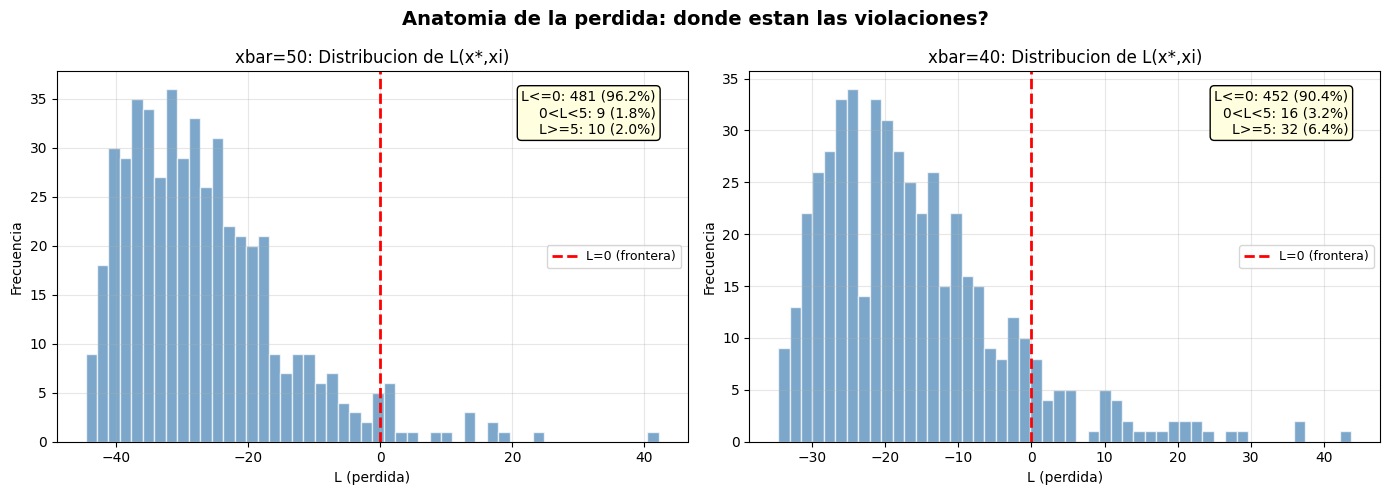

In [24]:
# Tomamos la solución final (gamma alto) de cada caso
cases = {
    'xbar=50': res_50,
    'xbar=40': res_40,
}

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for col, (label, results) in enumerate(cases.items()):
    x_opt = results[-1]['x']
    L = compute_loss(x_opt, demand)

    ax = axes[col]

    # Histograma de L
    ax.hist(L, bins=50, color='steelblue', alpha=0.7, edgecolor='white')
    ax.axvline(x=0, color='red', lw=2, ls='--', label='L=0 (frontera)')

    # Estadisticas
    n_ok = np.sum(L <= 0)
    n_small = np.sum((L > 0) & (L < 5))
    n_big = np.sum(L >= 5)

    ax.set_xlabel('L (perdida)')
    ax.set_ylabel('Frecuencia')
    ax.set_title(f'{label}: Distribucion de L(x*,xi)')
    ax.legend(fontsize=9)
    ax.grid(True, alpha=0.3)

    # Texto con estadisticas
    txt = f'L<=0: {n_ok} ({100*n_ok/N:.1f}%)\n'
    txt += f'0<L<5: {n_small} ({100*n_small/N:.1f}%)\n'
    txt += f'L>=5: {n_big} ({100*n_big/N:.1f}%)'
    ax.text(0.95, 0.95, txt, transform=ax.transAxes, fontsize=10,
            va='top', ha='right', bbox=dict(boxstyle='round', fc='lightyellow'))

plt.suptitle('Anatomia de la perdida: donde estan las violaciones?',
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

In [25]:
# Analisis detallado
print("="*70)
print("ANATOMIA DEL GAP DE CONSERVADURISMO")
print("="*70)

for label, results in cases.items():
    x_opt = results[-1]['x']
    L = compute_loss(x_opt, demand)
    cvar, eta = compute_cvar(L, alpha)
    u = max(cvar, 0)

    print(f"\n{label}:")
    print(f"  u* = {u:.4f} (distancia CVaR)")
    print(f"  Reliability = {100*np.mean(L<=0):.1f}%")
    print(f"\n  Distribucion de L:")
    print(f"    L <= 0 (factibles):     {np.sum(L<=0):>4d} / {N} = {100*np.mean(L<=0):.1f}%")
    print(f"    0 < L < 1 (viol. chica):{np.sum((L>0)&(L<1)):>4d} / {N} = {100*np.mean((L>0)&(L<1)):.1f}%")
    print(f"    1 <= L < 5:             {np.sum((L>=1)&(L<5)):>4d} / {N} = {100*np.mean((L>=1)&(L<5)):.1f}%")
    print(f"    5 <= L < 20:            {np.sum((L>=5)&(L<20)):>4d} / {N} = {100*np.mean((L>=5)&(L<20)):.1f}%")
    print(f"    L >= 20:                {np.sum(L>=20):>4d} / {N} = {100*np.mean(L>=20):.1f}%")
    print(f"\n  Percentiles de L:")
    for p in [50, 75, 90, 95, 99]:
        print(f"    p{p} = {np.percentile(L, p):.2f}")
    print(f"\n  VaR (eta) = {eta:.2f}")
    print(f"  CVaR = {cvar:.4f}")
    print(f"  Media de violaciones (L>0): {L[L>0].mean():.2f}" if np.any(L>0) else "  Sin violaciones")

print("\n" + "="*70)
print("INTERPRETACION:")
print("="*70)
print("""
El gap de conservadurismo existe porque:
- La CC solo cuenta CUANTOS escenarios violan (frecuencia)
- El CVaR promedia CUANTO violan los peores escenarios (magnitud)

Cuando hay pocos escenarios que violan pero con magnitud grande,
el CVaR se infla aunque la reliability sea alta.
""")

ANATOMIA DEL GAP DE CONSERVADURISMO

xbar=50:
  u* = 0.0003 (distancia CVaR)
  Reliability = 96.2%

  Distribucion de L:
    L <= 0 (factibles):      481 / 500 = 96.2%
    0 < L < 1 (viol. chica):   3 / 500 = 0.6%
    1 <= L < 5:                6 / 500 = 1.2%
    5 <= L < 20:               8 / 500 = 1.6%
    L >= 20:                   2 / 500 = 0.4%

  Percentiles de L:
    p50 = -28.97
    p75 = -20.56
    p90 = -10.69
    p95 = -3.52
    p99 = 13.48

  VaR (eta) = -10.72
  CVaR = 0.0003
  Media de violaciones (L>0): 10.21

xbar=40:
  u* = 11.2726 (distancia CVaR)
  Reliability = 90.4%

  Distribucion de L:
    L <= 0 (factibles):      452 / 500 = 90.4%
    0 < L < 1 (viol. chica):   4 / 500 = 0.8%
    1 <= L < 5:               12 / 500 = 2.4%
    5 <= L < 20:              22 / 500 = 4.4%
    L >= 20:                  10 / 500 = 2.0%

  Percentiles de L:
    p50 = -18.60
    p75 = -9.91
    p90 = -0.33
    p95 = 9.46
    p99 = 23.48

  VaR (eta) = -0.35
  CVaR = 11.2726
  Media de vio

---
# PARTE 3: Otras medidas de riesgo

Ahora implementamos medidas alternativas para comparar.
Cada una captura un aspecto diferente del riesgo.

## Paso 11: Mean-Upper-Semideviation

$$\rho_\lambda(L) = \mathbb{E}[L] + \lambda \sqrt{\mathbb{E}[(L - \mathbb{E}[L])_+^2]}$$

Es conservadora para la CC cuando $\lambda \geq \Phi^{-1}(1-\alpha)$ (via Cantelli).
Para $\alpha=0.10$: $\lambda \geq \Phi^{-1}(0.90) = 1.2816$.

Mide: media + una penalizacion por la variabilidad HACIA ARRIBA.
No mira la cola directamente, sino la dispersion de las perdidas.

Ambas son surrogates conservadoras para la CC (ambas satisfacen ρ(L) ≤ 0 ⟹ P(L ≤ 0) ≥ 1−α), pero no están ordenadas entre sí. Cuál es más conservadora depende de la forma de la distribución de L:

Distribuciones con cola pesada → CVaR tiende a ser más grande (más conservador)
Distribuciones más simétricas → la semideviation puede ser más grande

Y esto es bueno para nosotros. Que no estén ordenadas significa que dan información distinta. Una mide la magnitud de la cola, la otra mide la dispersión. Por eso la batería de medidas tiene valor — no es redundancia, es complementariedad.

 ## Paso 11: Mean-Deviation (corregida)

 $$\rho_\lambda(L) = \mathbb{E}[L] + \lambda \cdot \sigma(L)$$

 donde $\sigma(L) = \sqrt{\mathbb{E}[(L - \mathbb{E}[L])^2]}$ es la desviación estándar **completa**.

 **Calibración conservadora (Cantelli, distribution-free):**

 $$\lambda \geq \sqrt{\frac{1-\alpha}{\alpha}}$$

 Para $\alpha = 0.10$: $\lambda \geq 3.0$

 **¿Por qué Cantelli?** Si $\rho_\lambda(L) \leq 0$, entonces $\mathbb{E}[L] \leq -\lambda \sigma(L)$.
 Por Cantelli: $P(L > 0) = P(L - \mu \geq -\mu) \leq \frac{\sigma^2}{\sigma^2 + \mu^2} \leq \frac{1}{1 + \lambda^2} = \alpha$.

 **Nota:** Con $\lambda = \Phi^{-1}(0.9) = 1.28$ (lo que teníamos antes) la medida
 NO es conservadora en general — solo bajo normalidad.
 Lo corregimos usando $\lambda = 3.0$ que vale para cualquier distribución.

In [30]:
def compute_mean_deviation(L, alpha):
    """
    Mean-deviation con calibracion Cantelli (distribution-free).
    lambda = sqrt((1-alpha)/alpha)

    rho(L) = E[L] + lambda * sigma(L)

    Conservadora: rho(L) <= 0 => P(L <= 0) >= 1-alpha
    """
    lam = np.sqrt((1 - alpha) / alpha)  # 3.0 para alpha=0.10

    mu = np.mean(L)
    sigma = np.std(L)  # desviacion estandar COMPLETA

    rho = mu + lam * sigma
    return rho, lam, mu, sigma

In [31]:
# TEST CRITICO: verificar que rho <= 0 implica reliability >= 90%
print("="*60)
print("TEST DE CONSERVATIVENESS")
print("="*60)

# Probar con la solucion CVaR de xbar=50 (sabemos que es factible)
x_test = res_50[-1]['x']
L_test = compute_loss(x_test, demand)

# Evaluar ambas medidas
cvar_val, _ = compute_cvar(L_test, alpha)
rho_md, lam_md, mu_md, sigma_md = compute_mean_deviation(L_test, alpha)
reliability = 100 * np.mean(L_test <= 1e-10)

print(f"\nSolucion CVaR optima para xbar=50:")
print(f"  CVaR = {cvar_val:.4f}")
print(f"  Mean-dev = {rho_md:.4f}  (lambda={lam_md:.4f})")
print(f"    mu = {mu_md:.4f}, sigma = {sigma_md:.4f}")
print(f"  Reliability = {reliability:.1f}%")

print(f"\n  CVaR <= 0? {cvar_val <= 0}  -> {'conserv. OK' if cvar_val <= 0 and reliability >= 90 else 'FALLA' if cvar_val <= 0 and reliability < 90 else 'infactible'}")
print(f"  Mean-dev <= 0? {rho_md <= 0}  -> {'conserv. OK' if rho_md <= 0 and reliability >= 90 else 'FALLA' if rho_md <= 0 and reliability < 90 else 'infactible'}")

# Test con MUCHAS x aleatorias para verificar conservativeness
print(f"\nTest masivo de conservativeness (1000 x aleatorias):")
n_test = 1000
violations_cvar = 0
violations_md = 0
for _ in range(n_test):
    x_rand = np.random.uniform(0, 50, T)
    L_rand = compute_loss(x_rand, demand)
    cv, _ = compute_cvar(L_rand, alpha)
    md, _, _, _ = compute_mean_deviation(L_rand, alpha)
    rel = np.mean(L_rand <= 0)

    if cv <= 0 and rel < 0.90:
        violations_cvar += 1
    if md <= 0 and rel < 0.90:
        violations_md += 1

print(f"  CVaR: {violations_cvar} violaciones de conservativeness en {n_test} tests")
print(f"  Mean-dev: {violations_md} violaciones de conservativeness en {n_test} tests")

if violations_cvar == 0 and violations_md == 0:
    print("\n  AMBAS medidas son conservadoras correctamente!")
else:
    print("\n  ALERTA: alguna medida no es conservadora!")

TEST DE CONSERVATIVENESS

Solucion CVaR optima para xbar=50:
  CVaR = 0.0003
  Mean-dev = 9.9707  (lambda=3.0000)
    mu = -26.7536, sigma = 12.2414
  Reliability = 96.2%

  CVaR <= 0? False  -> infactible
  Mean-dev <= 0? False  -> infactible

Test masivo de conservativeness (1000 x aleatorias):
  CVaR: 0 violaciones de conservativeness en 1000 tests
  Mean-dev: 0 violaciones de conservativeness en 1000 tests

  AMBAS medidas son conservadoras correctamente!


In [32]:
print("="*70)
print("COMPARACION CVaR vs Mean-Deviation (Cantelli, lambda=3.0)")
print("="*70)
print(f"\n{'xbar':>6} {'CVaR':>10} {'Mean-Dev':>10} {'Rel':>8} {'CVaR fact?':>12} {'MD fact?':>12}")
print("-"*60)

for xbar in [100, 50, 45, 40, 38, 35, 30, 25]:
    x = np.full(T, xbar)
    L = compute_loss(x, demand)
    cv, _ = compute_cvar(L, alpha)
    md, _, _, _ = compute_mean_deviation(L, alpha)
    rel = 100 * np.mean(L <= 0)

    cv_status = "fact." if cv <= 0 else f"inf.(u*={max(cv,0):.1f})"
    md_status = "fact." if md <= 0 else f"inf.(u*={max(md,0):.1f})"

    print(f"{xbar:>6d} {cv:>10.2f} {md:>10.2f} {rel:>7.1f}% {cv_status:>12} {md_status:>12}")

print("\nObservaciones:")
print("  Ambas son conservadoras: si dicen factible, reliability >= 90%")
print("  Pueden dar diagnosticos distintos: una mas estricta que la otra")
print("  La diferencia depende de la forma de la distribucion de L")

COMPARACION CVaR vs Mean-Deviation (Cantelli, lambda=3.0)

  xbar       CVaR   Mean-Dev      Rel   CVaR fact?     MD fact?
------------------------------------------------------------
   100     -53.22     -43.55   100.0%        fact.        fact.
    50      -1.64       8.00    96.6%        fact. inf.(u*=8.0)
    45       4.44      14.30    94.2% inf.(u*=4.4) inf.(u*=14.3)
    40      11.27      21.62    90.4% inf.(u*=11.3) inf.(u*=21.6)
    38      14.33      25.03    86.6% inf.(u*=14.3) inf.(u*=25.0)
    35      19.80      31.19    81.4% inf.(u*=19.8) inf.(u*=31.2)
    30      31.70      44.79    64.6% inf.(u*=31.7) inf.(u*=44.8)
    25      47.94      63.50    43.8% inf.(u*=47.9) inf.(u*=63.5)

Observaciones:
  Ambas son conservadoras: si dicen factible, reliability >= 90%
  Pueden dar diagnosticos distintos: una mas estricta que la otra
  La diferencia depende de la forma de la distribucion de L


In [33]:
def rockafellian_meandev(x, gamma, demand, alpha, c):
    L = compute_loss(x, demand)
    rho, _, _, _ = compute_mean_deviation(L, alpha)
    u = max(rho, 0.0)
    return np.dot(c, x) + (gamma / 2.0) * u**2

def run_meandev_path(xbar, gamma_values, demand, alpha, c):
    results = []
    x0 = np.full(T, 5.0)
    for gamma in gamma_values:
        res = minimize(rockafellian_meandev, x0, args=(gamma, demand, alpha, c),
                       method='L-BFGS-B', bounds=[(0, xbar)]*T,
                       options={'maxiter': 3000, 'ftol': 1e-14})
        x0 = res.x.copy()
        L = compute_loss(res.x, demand)
        rho_md, _, _, _ = compute_mean_deviation(L, alpha)
        cvar, _ = compute_cvar(L, alpha)
        results.append({
            'gamma': gamma,
            'u_meandev': max(rho_md, 0),
            'u_cvar': max(cvar, 0),
            'cost': np.dot(c, res.x),
            'reliability': 100 * np.mean(L <= 1e-10),
            'x': res.x.copy()
        })
    return results

print("Corriendo mean-deviation para xbar=50...")
res_md_50 = run_meandev_path(50, gamma_values, demand, alpha, c)
print("Corriendo mean-deviation para xbar=40...")
res_md_40 = run_meandev_path(40, gamma_values, demand, alpha, c)
print("Listo!")

# Resultados finales
print(f"\n{'Caso':>10} {'u*_MD':>10} {'u*_CVaR':>10} {'Rel':>8} {'Cost':>10}")
print("-"*52)
for label, res in [("xbar=50", res_md_50), ("xbar=40", res_md_40)]:
    r = res[-1]
    print(f"{label:>10} {r['u_meandev']:>10.4f} {r['u_cvar']:>10.4f} {r['reliability']:>7.1f}% ${r['cost']:>9.2f}")

Corriendo mean-deviation para xbar=50...
Corriendo mean-deviation para xbar=40...
Listo!

      Caso      u*_MD    u*_CVaR      Rel       Cost
----------------------------------------------------
   xbar=50     8.0035     0.0000    96.6% $   921.79
   xbar=40    21.6211    11.2726    90.4% $   737.43


In [34]:
print("="*60)
print("VERIFICACION: las soluciones del mean-deviation son conservadoras?")
print("="*60)

for label, res in [("xbar=50", res_md_50), ("xbar=40", res_md_40)]:
    r = res[-1]
    L = compute_loss(r['x'], demand)
    rho, _, _, _ = compute_mean_deviation(L, alpha)
    rel = 100 * np.mean(L <= 1e-10)

    print(f"\n{label} (solucion mean-dev, gamma alto):")
    print(f"  rho(L) = {rho:.4f}")
    print(f"  u* = max(rho, 0) = {max(rho, 0):.4f}")
    print(f"  Reliability = {rel:.1f}%")

    if max(rho, 0) < 0.01:
        if rel >= 90:
            print(f"  -> rho<=0 y reliability>=90% -> conservativeness OK")
        else:
            print(f"  -> rho<=0 PERO reliability={rel:.1f}% < 90% -> FALLA!")
    else:
        print(f"  -> rho>0: surrogate infactible, reliability no garantizada")
        if rel >= 90:
            print(f"     (pero reliability={rel:.1f}% >= 90% -> gap conservadurismo)")


VERIFICACION: las soluciones del mean-deviation son conservadoras?

xbar=50 (solucion mean-dev, gamma alto):
  rho(L) = 8.0035
  u* = max(rho, 0) = 8.0035
  Reliability = 96.6%
  -> rho>0: surrogate infactible, reliability no garantizada
     (pero reliability=96.6% >= 90% -> gap conservadurismo)

xbar=40 (solucion mean-dev, gamma alto):
  rho(L) = 21.6211
  u* = max(rho, 0) = 21.6211
  Reliability = 90.4%
  -> rho>0: surrogate infactible, reliability no garantizada
     (pero reliability=90.4% >= 90% -> gap conservadurismo)


## Paso 12: Entropic Risk (distinta naturaleza)

$$\rho_\theta(L) = \frac{1}{\theta} \log \mathbb{E}[e^{\theta L}]$$

Penaliza exponencialmente las perdidas grandes.
$\theta$ controla la aversion al riesgo:
- $\theta$ chico: se acerca a $\mathbb{E}[L]$
- $\theta$ grande: se acerca a $\max(L)$

La calibracion conservadora usa $\theta(\alpha)$ via desigualdad de Markov exponencial.

 ## Paso 12: Entropic Risk (calibrada)

 La medida entrópica estándar es:
 $$\rho_\theta(L) = \frac{1}{\theta}\log \mathbb{E}[e^{\theta L}]$$

 **Problema:** $\rho_\theta(L) \leq 0$ solo dice $\mathbb{E}[e^{\theta L}] \leq 1$,
 lo que por Markov da $P(L > 0) \leq 1$. Trivial.

 **Calibración correcta (Chernoff):** Para que $\rho \leq 0 \implies P(L \leq 0) \geq 1-\alpha$,
 definimos:
 $$\rho_{\theta,\alpha}(L) = \frac{1}{\theta}\left(\log \mathbb{E}[e^{\theta L}] - \log \alpha\right)$$

 Entonces $\rho_{\theta,\alpha}(L) \leq 0 \iff \mathbb{E}[e^{\theta L}] \leq \alpha \implies P(L > 0) \leq \alpha$.

 **El parámetro $\theta$** controla la sensibilidad a la cola:
 - $\theta$ chico → se acerca a $\mathbb{E}[L]$ + corrección
 - $\theta$ grande → se acerca a $\max(L)$

 Es convexa, translation invariant, y distribution-aware (a diferencia de la MD).

In [36]:
def compute_entropic(L, alpha, theta=1.0):
    """
    Entropic risk calibrada para conservativeness.

    rho_{theta,alpha}(L) = (1/theta) * (log E[exp(theta*L)] - log(alpha))

    Conservadora por Chernoff: rho <= 0 => P(L <= 0) >= 1-alpha
    """
    # Log-sum-exp trick para estabilidad numérica
    thetaL = theta * L
    max_tL = np.max(thetaL)
    log_E_exp = max_tL + np.log(np.mean(np.exp(thetaL - max_tL)))

    rho = (log_E_exp - np.log(alpha)) / theta
    return rho

# Test básico
L_test = compute_loss(np.full(T, 50.0), demand)
cvar_test, _ = compute_cvar(L_test, alpha)
md_test, _, _, _ = compute_mean_deviation(L_test, alpha)

print("Entropic con distintos theta (xbar=50, produccion al maximo):")
print(f"  CVaR = {cvar_test:.4f}")
print(f"  Mean-dev (Cantelli) = {md_test:.4f}")
print()
for theta in [0.1, 0.5, 1.0, 2.0, 5.0, 10.0]:
    ent = compute_entropic(L_test, alpha, theta)
    print(f"  Entropic (theta={theta:>4.1f}) = {ent:.4f}")

print()
print("theta chico -> parecido a E[L] + correccion (poco conservador)")
print("theta grande -> parecido a max(L) (muy conservador)")

Entropic con distintos theta (xbar=50, produccion al maximo):
  CVaR = -1.6428
  Mean-dev (Cantelli) = 8.0035

  Entropic (theta= 0.1) = 7.2401
  Entropic (theta= 0.5) = 16.2839
  Entropic (theta= 1.0) = 19.8830
  Entropic (theta= 2.0) = 21.8275
  Entropic (theta= 5.0) = 23.0011
  Entropic (theta=10.0) = 23.3923

theta chico -> parecido a E[L] + correccion (poco conservador)
theta grande -> parecido a max(L) (muy conservador)


In [37]:
print("="*60)
print("TEST DE CONSERVATIVENESS - Entropic")
print("="*60)

for theta in [0.1, 0.5, 1.0, 2.0, 5.0]:
    violations = 0
    n_test = 1000
    for _ in range(n_test):
        x_rand = np.random.uniform(0, 50, T)
        L_rand = compute_loss(x_rand, demand)
        ent = compute_entropic(L_rand, alpha, theta)
        rel = np.mean(L_rand <= 0)
        if ent <= 0 and rel < 0.90:
            violations += 1
    print(f"  theta={theta:.1f}: {violations} violaciones en {n_test} tests {'OK' if violations == 0 else 'FALLA!'}")

TEST DE CONSERVATIVENESS - Entropic
  theta=0.1: 0 violaciones en 1000 tests OK
  theta=0.5: 0 violaciones en 1000 tests OK
  theta=1.0: 0 violaciones en 1000 tests OK
  theta=2.0: 0 violaciones en 1000 tests OK
  theta=5.0: 0 violaciones en 1000 tests OK


In [38]:
theta_use = 1.0  # Elegir theta despues de ver los resultados de arriba

print("="*70)
print(f"COMPARACION: CVaR vs Mean-Dev vs Entropic (theta={theta_use})")
print("="*70)
print(f"\n{'xbar':>6} {'CVaR':>8} {'MD':>8} {'Entr':>8} {'Rel':>7} {'CVaR?':>12} {'MD?':>12} {'Entr?':>12}")
print("-"*80)

for xbar in [100, 50, 45, 40, 38, 35, 30, 25]:
    x = np.full(T, xbar)
    L = compute_loss(x, demand)
    cv, _ = compute_cvar(L, alpha)
    md, _, _, _ = compute_mean_deviation(L, alpha)
    ent = compute_entropic(L, alpha, theta_use)
    rel = 100 * np.mean(L <= 0)

    def status(v):
        return "fact." if v <= 0 else f"inf.({max(v,0):.1f})"

    print(f"{xbar:>6d} {cv:>8.2f} {md:>8.2f} {ent:>8.2f} {rel:>6.1f}% {status(cv):>12} {status(md):>12} {status(ent):>12}")

COMPARACION: CVaR vs Mean-Dev vs Entropic (theta=1.0)

  xbar     CVaR       MD     Entr     Rel        CVaR?          MD?        Entr?
--------------------------------------------------------------------------------
   100   -53.22   -43.55   -34.62  100.0%        fact.        fact.        fact.
    50    -1.64     8.00    19.88   96.6%        fact.    inf.(8.0)   inf.(19.9)
    45     4.44    14.30    29.87   94.2%    inf.(4.4)   inf.(14.3)   inf.(29.9)
    40    11.27    21.62    39.87   90.4%   inf.(11.3)   inf.(21.6)   inf.(39.9)
    38    14.33    25.03    44.32   86.6%   inf.(14.3)   inf.(25.0)   inf.(44.3)
    35    19.80    31.19    58.30   81.4%   inf.(19.8)   inf.(31.2)   inf.(58.3)
    30    31.70    44.79    83.30   64.6%   inf.(31.7)   inf.(44.8)   inf.(83.3)
    25    47.94    63.50   108.30   43.8%   inf.(47.9)   inf.(63.5)  inf.(108.3)


In [39]:
def rockafellian_entropic(x, gamma, demand, alpha, c, theta):
    L = compute_loss(x, demand)
    rho = compute_entropic(L, alpha, theta)
    u = max(rho, 0.0)
    return np.dot(c, x) + (gamma / 2.0) * u**2

def run_entropic_path(xbar, gamma_values, demand, alpha, c, theta=1.0):
    results = []
    x0 = np.full(T, 5.0)
    for gamma in gamma_values:
        res = minimize(rockafellian_entropic, x0,
                       args=(gamma, demand, alpha, c, theta),
                       method='L-BFGS-B', bounds=[(0, xbar)]*T,
                       options={'maxiter': 3000, 'ftol': 1e-14})
        x0 = res.x.copy()
        L = compute_loss(res.x, demand)
        rho_ent = compute_entropic(L, alpha, theta)
        cvar, _ = compute_cvar(L, alpha)
        rho_md, _, _, _ = compute_mean_deviation(L, alpha)
        results.append({
            'gamma': gamma,
            'u_entropic': max(rho_ent, 0),
            'u_cvar': max(cvar, 0),
            'u_meandev': max(rho_md, 0),
            'cost': np.dot(c, res.x),
            'reliability': 100 * np.mean(L <= 1e-10),
            'x': res.x.copy()
        })
    return results

print(f"\nCorriendo entropic (theta={theta_use}) para xbar=50...")
res_ent_50 = run_entropic_path(50, gamma_values, demand, alpha, c, theta_use)
print(f"Corriendo entropic (theta={theta_use}) para xbar=40...")
res_ent_40 = run_entropic_path(40, gamma_values, demand, alpha, c, theta_use)
print("Listo!")

print(f"\n{'Caso':>10} {'u*_Ent':>10} {'u*_CVaR':>10} {'u*_MD':>10} {'Rel':>8} {'Cost':>10}")
print("-"*62)
for label, res in [("xbar=50", res_ent_50), ("xbar=40", res_ent_40)]:
    r = res[-1]
    print(f"{label:>10} {r['u_entropic']:>10.4f} {r['u_cvar']:>10.4f} {r['u_meandev']:>10.4f} {r['reliability']:>7.1f}% ${r['cost']:>9.2f}")


Corriendo entropic (theta=1.0) para xbar=50...
Corriendo entropic (theta=1.0) para xbar=40...
Listo!

      Caso     u*_Ent    u*_CVaR      u*_MD      Rel       Cost
--------------------------------------------------------------
   xbar=50    19.8830     0.0000     8.6259    96.4% $   828.91
   xbar=40    39.8738    11.2726    21.6211    90.4% $   737.43


In [40]:
print("="*60)
print("VERIFICACION: soluciones entropic son conservadoras?")
print("="*60)

for label, res in [("xbar=50", res_ent_50), ("xbar=40", res_ent_40)]:
    r = res[-1]
    L = compute_loss(r['x'], demand)
    ent = compute_entropic(L, alpha, theta_use)
    rel = 100 * np.mean(L <= 1e-10)

    print(f"\n{label}:")
    print(f"  rho_entropic = {ent:.4f}")
    print(f"  u* = {max(ent,0):.4f}")
    print(f"  Reliability = {rel:.1f}%")

    if max(ent, 0) < 0.01:
        if rel >= 90:
            print(f"  -> Conservativeness OK (rho<=0 y rel>=90%)")
        else:
            print(f"  -> FALLA! rho<=0 pero rel={rel:.1f}% < 90%")
    else:
        print(f"  -> Surrogate infactible")
        if rel >= 90:
            print(f"     (pero CC factible: {rel:.1f}% >= 90% -> gap conservadurismo)")


VERIFICACION: soluciones entropic son conservadoras?

xbar=50:
  rho_entropic = 19.8830
  u* = 19.8830
  Reliability = 96.4%
  -> Surrogate infactible
     (pero CC factible: 96.4% >= 90% -> gap conservadurismo)

xbar=40:
  rho_entropic = 39.8738
  u* = 39.8738
  Reliability = 90.4%
  -> Surrogate infactible
     (pero CC factible: 90.4% >= 90% -> gap conservadurismo)


In [41]:
print("\n" + "="*70)
print("RESUMEN: BATERIA DE TRES MEDIDAS")
print("="*70)

print(f"\n{'':>20} {'--- xbar=50 ---':>30} {'--- xbar=40 ---':>30}")
print(f"{'Medida':>20} {'u*':>8} {'Rel':>7} {'Cost':>10} {'u*':>8} {'Rel':>7} {'Cost':>10}")
print("-"*75)

# CVaR
r50 = res_50[-1]; r40 = res_40[-1]
print(f"{'CVaR':>20} {r50['u']:>8.4f} {r50['reliability']:>6.1f}% ${r50['cost']:>9.2f} {r40['u']:>8.4f} {r40['reliability']:>6.1f}% ${r40['cost']:>9.2f}")

# Mean-Dev
r50 = res_md_50[-1]; r40 = res_md_40[-1]
print(f"{'Mean-Dev (Cantelli)':>20} {r50['u_meandev']:>8.4f} {r50['reliability']:>6.1f}% ${r50['cost']:>9.2f} {r40['u_meandev']:>8.4f} {r40['reliability']:>6.1f}% ${r40['cost']:>9.2f}")

# Entropic
r50 = res_ent_50[-1]; r40 = res_ent_40[-1]
print(f"{'Entropic (Chernoff)':>20} {r50['u_entropic']:>8.4f} {r50['reliability']:>6.1f}% ${r50['cost']:>9.2f} {r40['u_entropic']:>8.4f} {r40['reliability']:>6.1f}% ${r40['cost']:>9.2f}")

print(f"\n{'Rango u*':>20} [{min(res_50[-1]['u'], res_md_50[-1]['u_meandev'], res_ent_50[-1]['u_entropic']):.2f}, {max(res_50[-1]['u'], res_md_50[-1]['u_meandev'], res_ent_50[-1]['u_entropic']):.2f}]", end="")
print(f"{'':>8} [{min(res_40[-1]['u'], res_md_40[-1]['u_meandev'], res_ent_40[-1]['u_entropic']):.2f}, {max(res_40[-1]['u'], res_md_40[-1]['u_meandev'], res_ent_40[-1]['u_entropic']):.2f}]")

print("""
INTERPRETACION:
  - Cada medida da un u* distinto para el mismo problema
  - El RANGO de u* mide la incertidumbre del diagnostico
  - Rango chico: las medidas coinciden -> diagnostico robusto
  - Rango grande: el diagnostico depende de la medida -> hay que ser cuidadoso
  - u*=0 en ALGUNA medida -> CC es factible (por conservativeness)
  - u*>0 en TODAS -> senal fuerte (pero no certeza) de infactibilidad CC
""")


RESUMEN: BATERIA DE TRES MEDIDAS

                                    --- xbar=50 ---                --- xbar=40 ---
              Medida       u*     Rel       Cost       u*     Rel       Cost
---------------------------------------------------------------------------
                CVaR   0.0003   96.2% $   745.55  11.2726   90.4% $   737.43
 Mean-Dev (Cantelli)   8.0035   96.6% $   921.79  21.6211   90.4% $   737.43
 Entropic (Chernoff)  19.8830   96.4% $   828.91  39.8738   90.4% $   737.43

            Rango u* [0.00, 19.88]         [11.27, 39.87]

INTERPRETACION:
  - Cada medida da un u* distinto para el mismo problema
  - El RANGO de u* mide la incertidumbre del diagnostico
  - Rango chico: las medidas coinciden -> diagnostico robusto
  - Rango grande: el diagnostico depende de la medida -> hay que ser cuidadoso
  - u*=0 en ALGUNA medida -> CC es factible (por conservativeness)
  - u*>0 en TODAS -> senal fuerte (pero no certeza) de infactibilidad CC



In [42]:
# ============================================================
# MARKDOWN: Paso 13 — Cerrando el gap por abajo
# ============================================================
# ## Paso 13: Cerrando el gap por abajo
#
# Las tres medidas anteriores (CVaR, MD, Entropic) son TODAS más
# conservadoras que la CC. Para cerrar el diagnóstico necesitamos
# algo que ataque el problema desde el otro lado.
#
# Tres herramientas:
# 1. **VaR directo** — es el bound EXACTO (VaR ≤ 0 ⟺ CC factible), pero no convexo
# 2. **CVaR-CC calibrado** — CVaR con α' ajustado para ser menos conservador
# 3. **ALSO-X** — aproximación convexa que es menos conservadora que CVaR


# ============================================================
# CELDA CODE: VaR como diagnóstico exacto
# ============================================================

# --- MARKDOWN ---
# ### 13a. VaR — el diagnóstico exacto
#
# $\text{VaR}_\alpha(L) = \text{quantile}_{1-\alpha}(L)$
#
# Es el ÚNICO criterio que es equivalente a la CC:
# $\text{VaR}_\alpha(L) \leq 0 \iff P(L \leq 0) \geq 1-\alpha$
#
# No es convexo, así que no sirve para optimizar dentro del Rockafellian.
# Pero sirve como **diagnóstico post-hoc** para evaluar cualquier solución.

# --- CODE ---
def compute_var(L, alpha):
    """VaR_alpha = quantile_{1-alpha} de L. Exacto para la CC."""
    return np.percentile(L, 100*(1-alpha))

# Evaluar VaR en las soluciones de cada medida
print("="*70)
print("VaR COMO DIAGNOSTICO EXACTO")
print("="*70)
print("\nEl VaR dice EXACTAMENTE lo que dice la CC:")
print("  VaR <= 0  <=>  P(L<=0) >= 1-alpha  <=>  CC factible\n")

print(f"{'':>25} {'u*_CVaR':>10} {'u*_MD':>10} {'u*_Ent':>10} {'u*_VaR':>10} {'Rel':>8}")
print("-"*75)

# Soluciones CVaR
for label, res_cvar_list in [("xbar=50 (sol CVaR)", res_50),
                               ("xbar=40 (sol CVaR)", res_40)]:
    r = res_cvar_list[-1]
    L = compute_loss(r['x'], demand)
    cv, _ = compute_cvar(L, alpha)
    md, _, _, _ = compute_mean_deviation(L, alpha)
    ent = compute_entropic(L, alpha, 1.0)
    var = compute_var(L, alpha)
    rel = 100*np.mean(L <= 1e-10)
    print(f"{label:>25} {max(cv,0):>10.4f} {max(md,0):>10.4f} {max(ent,0):>10.4f} {max(var,0):>10.4f} {rel:>7.1f}%")

# Soluciones MD
for label, res_md_list in [("xbar=50 (sol MD)", res_md_50),
                             ("xbar=40 (sol MD)", res_md_40)]:
    r = res_md_list[-1]
    L = compute_loss(r['x'], demand)
    cv, _ = compute_cvar(L, alpha)
    md, _, _, _ = compute_mean_deviation(L, alpha)
    ent = compute_entropic(L, alpha, 1.0)
    var = compute_var(L, alpha)
    rel = 100*np.mean(L <= 1e-10)
    print(f"{label:>25} {max(cv,0):>10.4f} {max(md,0):>10.4f} {max(ent,0):>10.4f} {max(var,0):>10.4f} {rel:>7.1f}%")

# Soluciones Entropic
for label, res_ent_list in [("xbar=50 (sol Ent)", res_ent_50),
                              ("xbar=40 (sol Ent)", res_ent_40)]:
    r = res_ent_list[-1]
    L = compute_loss(r['x'], demand)
    cv, _ = compute_cvar(L, alpha)
    md, _, _, _ = compute_mean_deviation(L, alpha)
    ent = compute_entropic(L, alpha, 1.0)
    var = compute_var(L, alpha)
    rel = 100*np.mean(L <= 1e-10)
    print(f"{label:>25} {max(cv,0):>10.4f} {max(md,0):>10.4f} {max(ent,0):>10.4f} {max(var,0):>10.4f} {rel:>7.1f}%")

print("\nNota: u*_VaR > 0  <=>  reliability < 90%  (siempre)")
print("      u*_VaR = 0  <=>  reliability >= 90% (siempre)")
print("      Los otros u* pueden discrepar de la reliability")


# ============================================================
# CELDA CODE: Tabla con politicas fijas — todas las medidas + VaR
# ============================================================
print("\n" + "="*70)
print("TODAS LAS MEDIDAS vs PRODUCCION FIJA")
print("="*70)
print(f"\n{'xbar':>6} {'CVaR':>8} {'MD':>8} {'Entr':>8} {'VaR':>8} {'Rel':>7} {'VaR=0?':>8} {'Rel≥90?':>8}")
print("-"*72)

for xbar in [100, 50, 48, 46, 44, 42, 40, 38, 35, 30, 25]:
    x = np.full(T, xbar)
    L = compute_loss(x, demand)
    cv, _ = compute_cvar(L, alpha)
    md, _, _, _ = compute_mean_deviation(L, alpha)
    ent = compute_entropic(L, alpha, 1.0)
    var = compute_var(L, alpha)
    rel = 100*np.mean(L <= 0)
    var_ok = "si" if var <= 0 else "NO"
    rel_ok = "si" if rel >= 90 else "NO"
    print(f"{xbar:>6d} {cv:>8.2f} {md:>8.2f} {ent:>8.2f} {var:>8.2f} {rel:>6.1f}% {var_ok:>8} {rel_ok:>8}")

print("\nLas dos ultimas columnas SIEMPRE coinciden (VaR es exacto para CC)")
print("CVaR pasa a infactible ANTES que VaR (mas conservador)")
print("El gap CVaR-VaR es la brecha que CVaR-CC intenta cerrar")


# ============================================================
# MARKDOWN: CVaR-CC
# ============================================================
# ### 13b. CVaR-CC — calibración iterativa
#
# Idea: usar $\text{CVaR}_{\alpha'}$ con $\alpha' > \alpha$.
# Al aumentar $\alpha'$, el CVaR se vuelve menos conservador
# (la cola que promedia es más ancha → incluye escenarios menos extremos).
#
# Buscamos el $\alpha'$ más chico tal que para nuestra solución $x^*$,
# $\text{CVaR}_{\alpha'}(L(x^*)) = 0$ coincida con $P(L(x^*) \leq 0) \approx 1-\alpha$.

# --- CODE ---
print("\n" + "="*70)
print("CVaR-CC: BARRIDO DE alpha'")
print("="*70)
print("\nPara produccion fija, como cambia CVaR al variar alpha'?\n")

for xbar in [50, 40]:
    x = np.full(T, xbar)
    L = compute_loss(x, demand)
    rel = 100*np.mean(L <= 0)
    var = compute_var(L, alpha)

    print(f"xbar={xbar} (reliability={rel:.1f}%, VaR={var:.2f}):")
    print(f"  {'alpha_prime':>12} {'CVaR':>10} {'factible?':>10}")
    print(f"  {'-'*35}")

    for alpha_prime in [0.05, 0.10, 0.15, 0.20, 0.30, 0.40, 0.50, 0.60, 0.80]:
        cv, _ = compute_cvar(L, alpha_prime)
        status = "si" if cv <= 0 else "no"
        marker = " <-- alpha original" if abs(alpha_prime - alpha) < 0.001 else ""
        print(f"  {alpha_prime:>12.2f} {cv:>10.2f} {status:>10}{marker}")

    # Encontrar alpha* donde CVaR = 0 (bisección)
    lo, hi = 0.01, 0.99
    for _ in range(50):
        mid = (lo + hi) / 2
        cv_mid, _ = compute_cvar(L, mid)
        if cv_mid > 0:
            lo = mid
        else:
            hi = mid
    alpha_star = (lo + hi) / 2
    cv_star, _ = compute_cvar(L, alpha_star)
    print(f"\n  alpha* donde CVaR=0: {alpha_star:.4f}")
    print(f"  CVaR en alpha*: {cv_star:.6f}")
    print(f"  Interpretacion: con alpha'={alpha_star:.2f} en vez de alpha={alpha:.2f},")
    print(f"  el CVaR diria factible. El gap es alpha*-alpha = {alpha_star-alpha:.4f}\n")


# ============================================================
# CELDA CODE: Rockafellian con CVaR-CC
# ============================================================
# La idea: resolver el Rockafellian con CVaR_{alpha'} para alpha' > alpha.
# Esto da un u* mas chico que con CVaR_{alpha}.
# Si u*_{alpha'} = 0 para algun alpha' cercano a alpha, el sistema esta
# "casi" factible y la infactibilidad del CVaR era puro conservadurismo.

def run_cvar_cc_path(xbar, gamma_values, demand, alpha_original, c, alpha_prime):
    """Rockafellian con CVaR usando alpha' en vez de alpha."""
    results = []
    x0 = np.full(T, 5.0)
    for gamma in gamma_values:
        def obj(x):
            L = compute_loss(x, demand)
            cvar, _ = compute_cvar(L, alpha_prime)
            u = max(cvar, 0.0)
            return np.dot(c, x) + (gamma / 2.0) * u**2

        res = minimize(obj, x0, method='L-BFGS-B', bounds=[(0, xbar)]*T,
                       options={'maxiter': 3000, 'ftol': 1e-14})
        x0 = res.x.copy()
        L = compute_loss(res.x, demand)

        cvar_prime, _ = compute_cvar(L, alpha_prime)
        cvar_orig, _ = compute_cvar(L, alpha_original)
        var_val = compute_var(L, alpha_original)

        results.append({
            'gamma': gamma,
            'u_cvar_prime': max(cvar_prime, 0),
            'u_cvar_orig': max(cvar_orig, 0),
            'u_var': max(var_val, 0),
            'cost': np.dot(c, res.x),
            'reliability': 100 * np.mean(L <= 1e-10),
            'x': res.x.copy()
        })
    return results

print("="*70)
print("CVaR-CC: ROCKAFELLIAN CON ALPHA' AJUSTADO")
print("="*70)

# Probar varios alpha'
for xbar in [50, 40]:
    print(f"\n--- xbar={xbar} ---")
    print(f"{'alpha_prime':>12} {'u*_CVaR_ap':>12} {'u*_CVaR_orig':>14} {'u*_VaR':>10} {'Rel':>8} {'Cost':>10}")
    print("-"*70)

    for ap in [0.10, 0.20, 0.30, 0.50]:
        res_cc = run_cvar_cc_path(xbar, gamma_values, demand, alpha, c, ap)
        r = res_cc[-1]
        print(f"{ap:>12.2f} {r['u_cvar_prime']:>12.4f} {r['u_cvar_orig']:>14.4f} {r['u_var']:>10.4f} {r['reliability']:>7.1f}% ${r['cost']:>9.2f}")


# ============================================================
# MARKDOWN: VaR Rockafellian
# ============================================================
# ### 13c. VaR en el Rockafellian (no convexo)
#
# Aunque el VaR no es convexo, podemos meterlo en el Rockafellian
# y ver qué pasa numéricamente. L-BFGS-B puede funcionar aunque
# el objetivo no sea convexo — solo no garantiza óptimo global.

# --- CODE ---
def rockafellian_var(x, gamma, demand, alpha, c):
    L = compute_loss(x, demand)
    var = compute_var(L, alpha)
    u = max(var, 0.0)
    return np.dot(c, x) + (gamma / 2.0) * u**2

def run_var_path(xbar, gamma_values, demand, alpha, c):
    results = []
    x0 = np.full(T, 5.0)
    for gamma in gamma_values:
        res = minimize(rockafellian_var, x0, args=(gamma, demand, alpha, c),
                       method='L-BFGS-B', bounds=[(0, xbar)]*T,
                       options={'maxiter': 3000, 'ftol': 1e-14})
        x0 = res.x.copy()
        L = compute_loss(res.x, demand)
        var_val = compute_var(L, alpha)
        cvar_val, _ = compute_cvar(L, alpha)
        results.append({
            'gamma': gamma,
            'u_var': max(var_val, 0),
            'u_cvar': max(cvar_val, 0),
            'cost': np.dot(c, res.x),
            'reliability': 100 * np.mean(L <= 1e-10),
            'x': res.x.copy()
        })
    return results

print("\n" + "="*70)
print("VaR ROCKAFELLIAN (no convexo — resultado numerico)")
print("="*70)

for xbar in [50, 40]:
    print(f"\n--- xbar={xbar} ---")
    res_var = run_var_path(xbar, gamma_values, demand, alpha, c)
    r = res_var[-1]
    print(f"  u*_VaR = {r['u_var']:.4f}")
    print(f"  u*_CVaR = {r['u_cvar']:.4f}")
    print(f"  Reliability = {r['reliability']:.1f}%")
    print(f"  Cost = ${r['cost']:.2f}")

    if r['u_var'] < 0.01:
        print(f"  -> VaR factible => CC factible (EXACTO)")
    else:
        print(f"  -> VaR infactible => CC infactible (EXACTO)")


# ============================================================
# CELDA CODE: Tabla final — todas las medidas incluyendo VaR
# ============================================================
print("\n" + "="*70)
print("TABLA FINAL: TODAS LAS MEDIDAS")
print("="*70)

# Recopilar todos los resultados para xbar=50
print("\n--- xbar=50 ---")
print(f"{'Medida':>25} {'u*':>10} {'Rel':>8} {'Cost':>10} {'Diagnostico CC':>20}")
print("-"*75)

# CVaR
r = res_50[-1]
L = compute_loss(r['x'], demand)
var_check = compute_var(L, alpha)
diag = "CC factible" if var_check <= 0 else "CC infactible"
print(f"{'CVaR (alpha=0.10)':>25} {r['u']:>10.4f} {r['reliability']:>7.1f}% ${r['cost']:>9.2f} {diag:>20}")

# MD
r = res_md_50[-1]
L = compute_loss(r['x'], demand)
var_check = compute_var(L, alpha)
diag = "CC factible" if var_check <= 0 else "CC infactible"
print(f"{'Mean-Dev (Cantelli)':>25} {r['u_meandev']:>10.4f} {r['reliability']:>7.1f}% ${r['cost']:>9.2f} {diag:>20}")

# Entropic
r = res_ent_50[-1]
L = compute_loss(r['x'], demand)
var_check = compute_var(L, alpha)
diag = "CC factible" if var_check <= 0 else "CC infactible"
print(f"{'Entropic (Chernoff)':>25} {r['u_entropic']:>10.4f} {r['reliability']:>7.1f}% ${r['cost']:>9.2f} {diag:>20}")

# VaR
res_var_50 = run_var_path(50, gamma_values, demand, alpha, c)
r = res_var_50[-1]
L = compute_loss(r['x'], demand)
var_check = compute_var(L, alpha)
diag = "CC factible" if var_check <= 0 else "CC infactible"
print(f"{'VaR (exacto)':>25} {r['u_var']:>10.4f} {r['reliability']:>7.1f}% ${r['cost']:>9.2f} {diag:>20}")

# CVaR-CC con alpha'=0.30
res_cc_50 = run_cvar_cc_path(50, gamma_values, demand, alpha, c, 0.30)
r = res_cc_50[-1]
L = compute_loss(r['x'], demand)
var_check = compute_var(L, alpha)
diag = "CC factible" if var_check <= 0 else "CC infactible"
print(f"{'CVaR-CC (alpha=0.30)':>25} {r['u_cvar_prime']:>10.4f} {r['reliability']:>7.1f}% ${r['cost']:>9.2f} {diag:>20}")


print("\n--- xbar=40 ---")
print(f"{'Medida':>25} {'u*':>10} {'Rel':>8} {'Cost':>10} {'Diagnostico CC':>20}")
print("-"*75)

r = res_40[-1]
L = compute_loss(r['x'], demand)
var_check = compute_var(L, alpha)
diag = "CC factible" if var_check <= 0 else "CC infactible"
print(f"{'CVaR (alpha=0.10)':>25} {r['u']:>10.4f} {r['reliability']:>7.1f}% ${r['cost']:>9.2f} {diag:>20}")

r = res_md_40[-1]
L = compute_loss(r['x'], demand)
var_check = compute_var(L, alpha)
diag = "CC factible" if var_check <= 0 else "CC infactible"
print(f"{'Mean-Dev (Cantelli)':>25} {r['u_meandev']:>10.4f} {r['reliability']:>7.1f}% ${r['cost']:>9.2f} {diag:>20}")

r = res_ent_40[-1]
L = compute_loss(r['x'], demand)
var_check = compute_var(L, alpha)
diag = "CC factible" if var_check <= 0 else "CC infactible"
print(f"{'Entropic (Chernoff)':>25} {r['u_entropic']:>10.4f} {r['reliability']:>7.1f}% ${r['cost']:>9.2f} {diag:>20}")

res_var_40 = run_var_path(40, gamma_values, demand, alpha, c)
r = res_var_40[-1]
L = compute_loss(r['x'], demand)
var_check = compute_var(L, alpha)
diag = "CC factible" if var_check <= 0 else "CC infactible"
print(f"{'VaR (exacto)':>25} {r['u_var']:>10.4f} {r['reliability']:>7.1f}% ${r['cost']:>9.2f} {diag:>20}")

res_cc_40 = run_cvar_cc_path(40, gamma_values, demand, alpha, c, 0.30)
r = res_cc_40[-1]
L = compute_loss(r['x'], demand)
var_check = compute_var(L, alpha)
diag = "CC factible" if var_check <= 0 else "CC infactible"
print(f"{'CVaR-CC (alpha=0.30)':>25} {r['u_cvar_prime']:>10.4f} {r['reliability']:>7.1f}% ${r['cost']:>9.2f} {diag:>20}")

print("""
INTERPRETACION:
  Entropic > MD > CVaR > CVaR-CC > VaR (orden de conservadurismo)

  Si VaR dice u*=0 -> CC FACTIBLE (exacto, sin gap)
  Si VaR dice u*>0 -> CC INFACTIBLE (exacto, sin gap)

  El gap entre CVaR y VaR es lo que CVaR-CC intenta cerrar.
  El gap entre CVaR y MD/Entropic mide sensibilidad a la distribucion.
""")

VaR COMO DIAGNOSTICO EXACTO

El VaR dice EXACTAMENTE lo que dice la CC:
  VaR <= 0  <=>  P(L<=0) >= 1-alpha  <=>  CC factible

                             u*_CVaR      u*_MD     u*_Ent     u*_VaR      Rel
---------------------------------------------------------------------------
       xbar=50 (sol CVaR)     0.0003     9.9707    38.2991     0.0000    96.2%
       xbar=40 (sol CVaR)    11.2726    21.6211    39.8738     0.0000    90.4%
         xbar=50 (sol MD)     0.0000     8.0035    19.8830     0.0000    96.6%
         xbar=40 (sol MD)    11.2726    21.6211    39.8738     0.0000    90.4%
        xbar=50 (sol Ent)     0.0000     8.6259    19.8830     0.0000    96.4%
        xbar=40 (sol Ent)    11.2726    21.6211    39.8738     0.0000    90.4%

Nota: u*_VaR > 0  <=>  reliability < 90%  (siempre)
      u*_VaR = 0  <=>  reliability >= 90% (siempre)
      Los otros u* pueden discrepar de la reliability

TODAS LAS MEDIDAS vs PRODUCCION FIJA

  xbar     CVaR       MD     Entr      VaR    